# COMP 551 Assignment 3

## Task 1: Acquire the data

In [198]:
#!pip install torchvision

In [199]:
import torch
import numpy as np
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

### **Step 1: Load Dataset**

In [200]:
# dataset objects: .data = all images (N, 28, 28), uint8 0-255; .targets = labels
# dataset[i] applies ToTensor -> image [1, 28, 28], float 0-1
train_dataset_raw = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transforms.ToTensor())
test_dataset_raw = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transforms.ToTensor())

In [201]:
image, label = train_dataset_raw[0]
print(type(image))
print(image.shape)
print(image.dtype)
print(image.device)
print(f"Train partition: {train_dataset_raw.data.shape} {len(train_dataset_raw)} images")
print(f"Test partition: {test_dataset_raw.data.shape} {len(test_dataset_raw)} images")

<class 'torch.Tensor'>
torch.Size([1, 28, 28])
torch.float32
cpu
Train partition: torch.Size([60000, 28, 28]) 60000 images
Test partition: torch.Size([10000, 28, 28]) 10000 images


### **Step 2: Split Training Partition**

In [202]:
""" Split the default training partition (60k images)
into training and validation partitions """

from torch.utils.data import Subset

split_ratio = 0.8
split_point = int(split_ratio * len(train_dataset_raw))

rng = np.random.default_rng(2026)
indices = np.arange(len(train_dataset_raw))
rng.shuffle(indices)
train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_set = Subset(train_dataset_raw, train_indices)
val_set   = Subset(train_dataset_raw, val_indices)

print(f"Train size: {len(train_set)}")
print(f"Validation size: {len(val_set)}")

Train size: 48000
Validation size: 12000


### **Step 3: Flatten Dataset**

In [203]:
# bring subsets into numpy (raw images)
X_train = train_dataset_raw.data.numpy()[train_indices]
X_val   = train_dataset_raw.data.numpy()[val_indices]
X_test  = test_dataset_raw.data.numpy()

print(f'X_train: {X_train.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_test: {X_test.shape}')

# labels
y_train = train_dataset_raw.targets.numpy()[train_indices]
y_val   = train_dataset_raw.targets.numpy()[val_indices]
y_test  = test_dataset_raw.targets.numpy()

# flatten [vectorize 28*28 = 784]
x_train = X_train.reshape(-1, 784).astype(np.float32) # convert to float
x_val = X_val.reshape(-1, 784).astype(np.float32)
x_test = X_test.reshape(-1, 784).astype(np.float32)

print(f'\nx_val: {x_val.shape}')
print(f'x_train: {x_train.shape}')
print(f'x_test: {x_test.shape}')

# keep unnormalized copies for Q4
x_train_raw, x_val_raw, x_test_raw = x_train.copy(), x_val.copy(), x_test.copy()

X_train: (48000, 28, 28)
X_val: (12000, 28, 28)
X_test: (10000, 28, 28)

x_val: (12000, 784)
x_train: (48000, 784)
x_test: (10000, 784)


### **Step 4: Normalize Dataset**

In [204]:
# normalization statistics from the training split only (not validation)
# this method based on numpy simplicity in the CS231n data processing reference

mean = x_train.mean()
std = x_train.std()
print(f'train mean: {mean:.3f}, train std: {std:.3f}')

# apply the same mean and std to all three sets
x_train = (x_train - mean) / std
x_val   = (x_val - mean) / std
x_test  = (x_test - mean) / std

print(f'train: mean {x_train.mean():.3f}, std {x_train.std():.3f}')
print(f'val:   mean {x_val.mean():.3f}, std {x_val.std():.3f}')
print(f'test:  mean {x_test.mean():.3f}, std {x_test.std():.3f}')

train mean: 72.877, train std: 90.006
train: mean -0.000, std 1.000
val:   mean 0.003, std 1.001
test:  mean 0.003, std 0.999


### **Step 5: Exploratory Data Analysis**

In [205]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

#### 1. Dataset structure

In [206]:
for root, dirs, files in os.walk('./data/FashionMNIST'):

    level = root.replace('./data/FashionMNIST', "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:]:
        print(f"{indent}    {file}")

print(train_dataset_raw)
print("Images shape:", train_dataset_raw.data.shape)
print("Labels shape:", train_dataset_raw.targets.shape)
class_names = train_dataset_raw.classes

print("Number of classes:", len(class_names))
for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)


FashionMNIST/
    raw/
        t10k-images-idx3-ubyte
        t10k-labels-idx1-ubyte
        train-images-idx3-ubyte
        t10k-images-idx3-ubyte.gz
        train-images-idx3-ubyte.gz
        train-labels-idx1-ubyte.gz
        train-labels-idx1-ubyte
        t10k-labels-idx1-ubyte.gz
Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Images shape: torch.Size([60000, 28, 28])
Labels shape: torch.Size([60000])
Number of classes: 10
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot


#### 2. Class Distribution - images per category

         Class  Train  Validation  Test  Total
0  T-shirt/top   4755        1245  1000   7000
1      Trouser   4852        1148  1000   7000
2     Pullover   4803        1197  1000   7000
3        Dress   4810        1190  1000   7000
4         Coat   4775        1225  1000   7000
5       Sandal   4819        1181  1000   7000
6        Shirt   4791        1209  1000   7000
7      Sneaker   4765        1235  1000   7000
8          Bag   4834        1166  1000   7000
9   Ankle boot   4796        1204  1000   7000


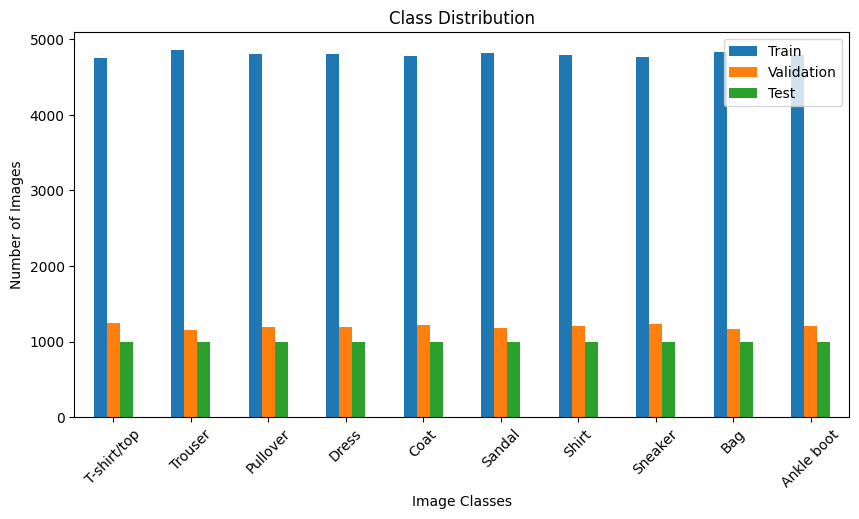

In [207]:
class_names = train_dataset_raw.classes

splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

class_counts = {"Class": class_names}

for split_name, labels in splits.items():
    class_counts[split_name] = np.bincount(labels, minlength=10)

class_df = pd.DataFrame(class_counts)
class_df["Total"] = class_df[["Train", "Validation", "Test"]].sum(axis=1)

print(class_df)

class_df.plot(
    kind="bar",
    x="Class",
    y=["Train", "Validation", "Test"],
    figsize=(10, 5)
)

plt.title("Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

#### 3. Random raw images

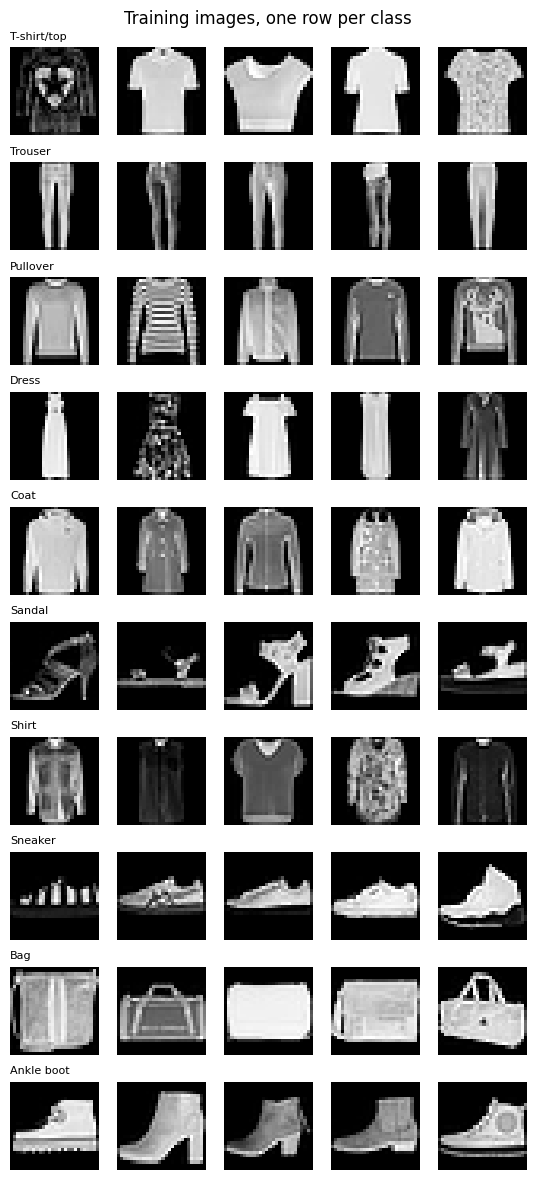

In [208]:
n_show = 5
fig, axes = plt.subplots(10, n_show, figsize=(n_show * 1.1, 10 * 1.2))
for c in range(10):
    examples = np.where(y_train == c)[0][:n_show]
    for j, i in enumerate(examples):
        axes[c, j].imshow(x_train[i].reshape(28, 28), cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=8, loc='left')
plt.suptitle('Training images, one row per class')
plt.tight_layout()
plt.show()

#### 4.Pixel distribution — mean, std, intensity

raw train pixels: mean 72.88, std 90.01


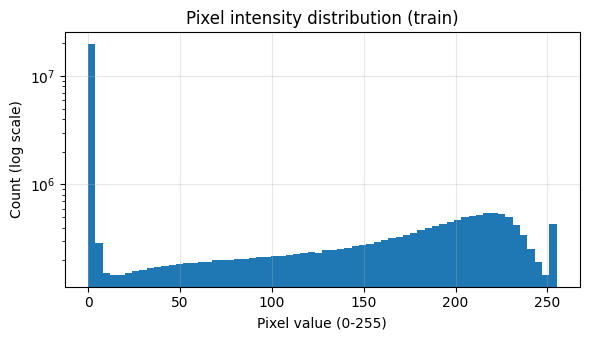

In [209]:
x_all_train = train_dataset_raw.data.numpy()
y_all_train = train_dataset_raw.targets.numpy()
x_all_test  = test_dataset_raw.data.numpy()
y_all_test  = test_dataset_raw.targets.numpy()

X_train_hist = x_all_train[train_indices]   # same split as the rest of the notebook

print(f'raw train pixels: mean {X_train_hist.mean():.2f}, std {X_train_hist.std():.2f}')

plt.figure(figsize=(6, 3.5))
plt.hist(X_train_hist.ravel(), bins=64, log=True)
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count (log scale)')
plt.title('Pixel intensity distribution (train)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Data integrity -- corrupted images


In [210]:
invalid = []
for i in range(len(train_dataset_raw)):              # reading every image like during training
    try:
        img, lable = train_dataset_raw[i]
    except Exception as e:
        invalid.append(("train", i))
for i in range(len(test_dataset_raw)):
    try:
        img, lable = test_dataset_raw[i]
    except Exception as e:
        invalid.append(('test', i))
print(f"Invalid images: {len(invalid)}")

for name, x, y in [('train partition', x_all_train, y_all_train), ('test partition', x_all_test, y_test)]:
    print(f"\n{name}:")
    print(f"  all images 28x28:        {x.shape[1:] == (28, 28)}")
    print(f"  pixel range:             [{x.min()}, {x.max()}]")
    print(f"  NaN values:              {np.isnan(x.astype(float)).sum()}")
    print(f"  labels in [0,9]:          {set(np.unique(y)) <= set(range(10))}")
    print(f"  completely blank images: {(x.reshape(len(x), -1).max(axis=1) == 0).sum()}")

Invalid images: 0

train partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0

test partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0


#### 6. Data leakage

In [211]:
# 6.1 image index in both training and validation
print(f"Indices shared by train and validation: {len(set(train_indices) & set(val_indices))}")

Indices shared by train and validation: 0


## Task 2: Implement a Multilayer Perceptron

Our model is an MLP with $L-1$ hidden layers and a softmax output layer:

$$
z_0 = x, \qquad
a_l = z_{l-1} W_l + b_l, \qquad
z_l = h(a_l) \quad \text{for } l = 1, \dots, L-1
$$

$$
\hat{y} = \operatorname{softmax}(a_L), \qquad a_L = z_{L-1} W_L + b_L
$$

$x$ is the flattened image (784 pixels), $h$ is the hidden activation function, $W_l$ and $b_l$ are the weights and bias for layer $l$, and $\hat{y}$ is the output probability of each of the 10 categories (softmax since it's multi-class).


An MLP is composed of three types of layers: 

(1) an input layer -> flattened 784 pixels

(2) hidden layers -> every layer: $z = h(Wx+b)$ (linear transformation -> activation function)

    - Activation Function: ReLU, Tanh, Leaky-ReLU

(3) an output layer -> the probability of 10 categories $\left ( \operatorname{softmax}(u)_k = \frac{\exp(u_k)}{\sum_j \exp(u_j)} \right )$

(4)Loss: 


$$L = -\frac{1}{N}\sum_{n}\sum_{k} y_{nk}\log \hat{y}_{nk}, \quad \hat{y} = \text{softmax}(a)$$

**Forward Pass:**

x --W1--> a1 --h--> z1 --W2--> a2 --h--> z2..... --Wl--> al --softmax--> yh --> L

#### Gradient

- Taking the derivative with respect to the last layer's pre-activation `a`:

$$\frac{\partial L}{\partial a} = \frac{\hat{y} - y}{N}$$

- $a = zW + b$

$$\frac{\partial L}{\partial w} = z^{T}  \frac{\partial L}{\partial a}$$
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} w^{T}$$

*Chain Rule*

For $ z = h(a_{l-1})$

$$\frac{\partial L}{\partial a_{l-1}} =  h'(a_{l-1}) \odot \frac{\partial L}{\partial z}$$

- h(): activation function 

Implementation should include 

    - backpropagation 

    - mini-batch gradient descent algorithm

- Leaky-ReLU slope γ is fixed at 0.01 here (making γ learnable would give PReLU, a possible extension)

- Weight Initialization

| Method                | Common application | Main idea                                      |
|-----------------------|--------------------|------------------------------------------------|
| Zero initialization   | Biases             | Initialize biases to zero                      |
| Random initialization | General concept    | Start weights with random values               |
| Xavier (Glorot)       | Tanh, sigmoid      | $\operatorname{Var}(W)=\frac{2}{n_{in}+n_{out}}$ |
| He (Kaiming)          | ReLU, Leaky ReLU   | $\operatorname{Var}(W)=\frac{2}{n_{in}}$         |


In [212]:
#Activation Function
relu = lambda a: np.maximum(0, a)
relu_grad = lambda a: (a > 0).astype(float)                          

tanh = lambda a: np.tanh(a)
tanh_grad = lambda a: 1 - np.tanh(a) ** 2                            

leaky_relu = lambda a: np.maximum(0, a) + 0.01 * np.minimum(0, a)     
leaky_relu_grad = lambda a: np.where(a > 0, 1., 0.01)

activations = {'relu': (relu, relu_grad),
               'tanh': (tanh, tanh_grad),
               'leaky_relu': (leaky_relu, leaky_relu_grad)}

In [213]:
#The constructor for the class should take as input 
# the activation function (e.g., ReLU), 
# the number of hidden layers (e.g., 2) 
# the number of units in the hidden layers (e.g., [64, 64]) 
# initialize the weights and biases (with an initializer of your choice) 
# as well as other important properties of the MLP.
def one_hot(y, C):
    Y = np.zeros((len(y), C))
    Y[np.arange(len(y)), y] = 1                 # e.g. label 3 -> [0,0,0,1,0,0,0,0,0,0]
    return Y

def softmax(a):
    a = a - np.max(a, axis=1, keepdims=True)    
    e = np.exp(a)
    return e / np.sum(e, axis=1, keepdims=True)

class MLP:
    
    def __init__(self, activation, n_hidden_layers, hidden_units, n_input , n_output, init = "default", L1 = 0, L2 = 0):
        '''
        Initialize a multilayer perceptron with a softmax output layer.

        Architecture: x -> [W1,b1] -> h -> [W2,b2] -> h -> ... -> [WL,bL] -> softmax -> yh

        Parameters:
        activation: hidden activation, 'relu', 'tanh' or 'leaky_relu'
        n_hidden_layers: number of hidden layers 
        hidden_units: list with the number of units of each hidden layer
        n_input: number of input features D
        n_output: number of classes C
        init: ReLU, Leaky ReLU, Tanh or default for 0.01
        '''
        self.activation = activation
        self.n_hidden_layers = n_hidden_layers
        self.hidden_units = hidden_units
        self.h, self.h_grad = activations[activation]
        self.input_dim = n_input
        self.output_dim = n_output
        self.init = init
        self.L1 = L1
        self.L2 = L2
        
        self.layer_sizes = [n_input] +list(hidden_units)+[n_output]
        # Store parameters as a list for the optimizer
        self.params = [] # [W1,b1,W2,b2,...,Wl,bl]

        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if init == 'relu' or init == "leaky_relu":
                scale = np.sqrt(2 / n_in)
            elif init == 'tanh':
                scale = np.sqrt(2 / (n_in + n_out))
            elif init == 'default':
                scale = .01
            else:
                raise ValueError(f"Unknown init: {init}")
            W = np.random.randn(n_in, n_out) * scale  # W_{i} (n_in, n_out)
            b = np.zeros(n_out)                         # (n_out,)

            self.params.extend([W, b])
            
    def forward(self, x, params):
        """
        Forward pass through the network.
        
        Parameters:
        x: input features, shape (N, D)
        params: [W1,b1,W2,b2,...,Wl,bl]
        Returns:
        out: predicted probabilities, shape (N, 10)
        
        """
        L = len(params) // 2 # number of layers [W1,b1,W2,b2,...,Wl,bl]
        z = x
        h_u, p_a = [x],[]  
        for l in range(L):
            W, b = params[2*l], params[2*l+1]
            a = np.dot(z, W) + b # pre-activation 
            p_a.append(a) 
            if l < L - 1:   # without output layer, all hidden layers go through activation function
                z = self.h(a) # after activation
                h_u.append(z)     # h_u[l] the input of l-th layer
        yh = softmax(a)

        return yh, h_u, p_a
    
    def gradient(self, x, y, params):
        """
        Compute gradients for both layers using backpropagation.
        
        Parameters:
        x: input features, shape (N, D)
        y: true labels, shape (N,)
        params: list [w1, b1... wL, bL] 
        
        Returns:
        params: list [dw1, db1... dwL, dbL] containing gradients for W and b
        """
        N = x.shape[0]
        L = len(params) // 2 
        yh, h_u, p_a = self.forward(x, params)
        # Store gradients
        dparams = [None] * len(params) #[dW1, db1, dW2, db2, ...]
        
        da = (yh - one_hot(y, yh.shape[1])) / N # the derivative with respect to the last layer's pre-activation

        for l in reversed(range(L)):
             W = params[2 * l]
             dW = np.dot(h_u[l].T, da)
             dW = dW + self.L1 * np.sign(W) + self.L2 * W     ## changes: regularization
             db = np.sum(da, axis=0)
             dparams[2 * l], dparams[2 * l + 1] = dW, db
             if l > 0:
                dz = np.dot(da, W.T)
                da = dz * self.h_grad(p_a[l - 1])

        return dparams
    
            
    def fit(self, x, y, optimizer):
       
        self.params = optimizer.run(self.gradient, x, y, self.params)
        return self

    def predict(self, x):
        yh, _, _ = self.forward(x, self.params)
        return np.argmax(yh, axis=1)
    
def evaluate_acc(y, yh):                    
    return np.mean(y == yh)
        
 

### Mini-batch gradient descent (batch_size config)

In [214]:
class GradientDescent:

    # batch_size: N = full-batch GD, 64 = mini-batch (default), 1 = SGD
    def __init__(self, learning_rate, epochs = 10, batch_size = 64):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        
    def run(self, gradient_fn, x, y, params):

        N = x.shape[0] 
        for epoch in range(self.epochs):
            # shuffle the training data every epoch
            order = np.random.permutation(N)

            # select a batch of `batch_size` samples each time
            for i in range(0, N, self.batch_size):
                batch = order[i : i+self.batch_size]
                grad = gradient_fn(x[batch], y[batch], params)
                for p in range(len(params)):
                    params[p] -= self.learning_rate * grad[p]


            print(f"Epoch {epoch + 1}/{self.epochs} done")
        return params

In [215]:
np.random.seed(2026) # reset global RNG: same initial weights & GradientDescent shuffling, so runs are reproducible
model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
            n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=3, batch_size=64)
model.fit(x_train, y_train, optimizer)

print(evaluate_acc(y_val, model.predict(x_val)))   

Epoch 1/3 done
Epoch 2/3 done
Epoch 3/3 done
0.8773333333333333


## Task 3: Run the experiments and report

1. 
- an MLP with no hidden layers, i.e., it directly maps the inputs to outputs; (784 -> 10 -> softmax)
- an MLP with a single hidden layer having 256 units and ReLU activations; (784 -> 256 (ReLU)-> 10 -> softmax)
- an MLP with 2 hidden layers each having 256 units with ReLU activations. (784 -> 256 (ReLU) -> 256 (ReLU) ->10 -> softmax)

Have a softmax layer at the end. 
After training, compare the test accuracy of these three models on the FashionMNIST dataset. 
Comment on how non-linearity and network depth affects the accuracy. Are the results that you obtain expected?

In [216]:
# Learning-rate sweep on the 2-hidden-layer ReLU MLP (selected by VALIDATION accuracy)
lr_rows = []
for lr in [0.005, 0.01, 0.05, 0.1, 0.2]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=lr, epochs=10, batch_size=64))
    lr_rows.append({'learning rate': lr,
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(lr_rows).round(3)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,learning rate,train acc,val acc
0,0.005,0.886,0.873
1,0.010,0.901,0.879
2,0.050,0.930,0.888
3,0.100,0.932,0.887
4,0.200,0.932,0.888


In [217]:
# Batch-size sweep 
bs_rows = []
for bs in [32, 64, 128, 256]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=bs))
    bs_rows.append({'batch size': bs,
                    'epoch': int(np.ceil(len(x_train) / bs)),
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(bs_rows).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,batch size,epoch,train acc,val acc
0,32,1500,0.9406,0.8920
1,64,750,0.9296,0.8877
2,128,375,0.9195,0.8880
3,256,188,0.8958,0.8742


In [218]:
# 1: MLP with no hidden layer 
np.random.seed(2026)
model_0 = MLP(activation='relu', n_hidden_layers=0, hidden_units=[],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_0.fit(x_train, y_train, optimizer)

train_acc_0 = evaluate_acc(y_train, model_0.predict(x_train))
test_acc_0  = evaluate_acc(y_test,  model_0.predict(x_test))

# 2: MLP with 1 hidden layer (256 units, ReLU)
model_1 = MLP(activation='relu', n_hidden_layers=1, hidden_units=[256],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_1.fit(x_train, y_train, optimizer)

train_acc_1 = evaluate_acc(y_train, model_1.predict(x_train))
test_acc_1  = evaluate_acc(y_test,  model_1.predict(x_test))

# 3: MLP with 2 hidden layers (256 units each, ReLU)
model_2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
              n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_2.fit(x_train, y_train, optimizer)

train_acc_2 = evaluate_acc(y_train, model_2.predict(x_train))
test_acc_2  = evaluate_acc(y_test,  model_2.predict(x_test))
# result
print(f'No hidden layer -> train acc: {train_acc_0:.4f}, test acc: {test_acc_0:.4f}')
print(f'1 hidden layer -> train acc: {train_acc_1:.4f}, test acc: {test_acc_1:.4f}')
print(f'2 hidden layers -> train acc: {train_acc_2:.4f}, test acc: {test_acc_2:.4f}')


Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
No hidden layer -> train acc: 0.8620, test acc: 0.8364
1 hidden layer -> train acc: 0.9221, test acc: 0.8779
2 hidden layers -> train acc: 0.9376, test acc: 0.8795


In [219]:
q1_table = pd.DataFrame({
    'model':     ['No hidden layer', '1 hidden layer (256)', '2 hidden layers (256, 256)'],
    'train accuracy': [train_acc_0, train_acc_1, train_acc_2],
    'test accuracy':  [test_acc_0,  test_acc_1,  test_acc_2],
})
q1_table['train - test'] = q1_table['train accuracy'] - q1_table['test accuracy']   
q1_table.round(4)

# model_0 to model_1 shows the affect of non-linearity, train and test accuracy is not high, underfitting
# linear 

,model,train accuracy,test accuracy,train - test
0,No hidden layer,0.8620,0.8364,0.0256
1,1 hidden layer (256),0.9221,0.8779,0.0442
2,"2 hidden layers (256, 256)",0.9376,0.8795,0.0581


Take the one with 2 hidden layers, change activation:
1) tanh and 
2) Leaky-ReLU. 
After training these two models compare their test accuracies with model having ReLU activations. 

Comment on the performances of these models: which one is better and why? Are certain activations better than others? If the results are not as you expected, what could be the reason?

In [220]:
# 2 hidden layers with tanh activation
np.random.seed(2026)
model_tanh = MLP(activation='tanh', n_hidden_layers=2, hidden_units=[256, 256],
                 n_input=784, n_output=10, init='tanh')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_tanh.fit(x_train, y_train, optimizer)

train_acc_tanh = evaluate_acc(y_train, model_tanh.predict(x_train))
test_acc_tanh  = evaluate_acc(y_test,  model_tanh.predict(x_test))
print(f'tanh -> train acc: {train_acc_tanh:.4f}, test acc: {test_acc_tanh:.4f}')

# Q2-2: 2 hidden layers with Leaky-ReLU activation
model_leaky = MLP(activation='leaky_relu', n_hidden_layers=2, hidden_units=[256, 256],
                  n_input=784, n_output=10, init='leaky_relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_leaky.fit(x_train, y_train, optimizer)

train_acc_leaky = evaluate_acc(y_train, model_leaky.predict(x_train))
test_acc_leaky  = evaluate_acc(y_test,  model_leaky.predict(x_test))
print(f'Leaky-ReLU -> train acc: {train_acc_leaky:.4f}, test acc: {test_acc_leaky:.4f}')

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
tanh -> train acc: 0.9278, test acc: 0.8793
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Leaky-ReLU -> train acc: 0.9391, test acc: 0.8856


In [221]:
q2_table = pd.DataFrame({
    'activation': ['ReLU', 'Tanh', 'Leaky-ReLU'],
    'train accuracy':  [train_acc_2, train_acc_tanh, train_acc_leaky],
    'test accuracy':   [test_acc_2,  test_acc_tanh,  test_acc_leaky],
})
q2_table['train - test'] = q2_table['train accuracy'] - q2_table['test accuracy']
q2_table.round(4)

,activation,train accuracy,test accuracy,train - test
0,ReLU,0.9376,0.8795,0.0581
1,Tanh,0.9278,0.8793,0.0485
2,Leaky-ReLU,0.9391,0.8856,0.0535


In [222]:
# Dead units: hidden units whose pre-activation a <= 0 for validation sample
dead_rows = []
for name, m in [('ReLU', model_2), ('Leaky-ReLU', model_leaky)]:
    _, _, p_a = m.forward(x_val, m.params)          
    for l in range(2):                              # the 2 hidden layers
        a = p_a[l]
        dead_rows.append({'activation': name,
                          'layer': l + 1,
                          'dead units': np.mean(np.all(a <= 0, axis=0))})

pd.DataFrame(dead_rows)

,activation,layer,dead units
0,ReLU,1,0.0
1,ReLU,2,0.0
2,Leaky-ReLU,1,0.0
3,Leaky-ReLU,2,0.0


In [223]:
# Repeat with 5 seeds to check
seed_rows = []
for act in ['relu', 'tanh', 'leaky_relu']:
    for seed in [2024, 2025, 2026, 2027, 2028]:
        np.random.seed(seed)
        m = MLP(activation=act, n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init=act)
        m.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
        seed_rows.append({'activation': act, 'seed': seed,
                          'train accuracy': evaluate_acc(y_train, m.predict(x_train)),
                          'test accuracy':  evaluate_acc(y_test,  m.predict(x_test))})

seed_df = pd.DataFrame(seed_rows)
seed_df.groupby('activation')[['train accuracy', 'test accuracy']].agg(['mean', 'std']).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Ep

train accuracy         test accuracy        
                     mean     std          mean     std
activation                                             
leaky_relu         0.9343  0.0023        0.8793  0.0016
relu               0.9344  0.0036        0.8792  0.0026
tanh               0.9259  0.0030        0.8789  0.0022

independently add L1 and L2 regularization to the network and train the MLP in this way. 
- $$\text{L1:}\quad J = L + \lambda_1 \sum |W| \qquad \text{L2:}\quad J = L + \frac{\lambda_2}{2} \sum W^2$$
- $$\qquad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_1\,\text{sign}(W) \quad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_2 W$$

In [230]:
L1_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l1 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L1=lam)
    model_l1.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L1_rows.append({'lambda_1': lam,
                    'train accuracy': evaluate_acc(y_train, model_l1.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l1.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l1.predict(x_test))})

pd.DataFrame(L1_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_1,train accuracy,val accuracy,test accuracy
0,0.000000,0.929583,0.887667,0.8771
1,0.000001,0.931438,0.891333,0.8807
2,0.000010,0.931250,0.892250,0.8783
3,0.000100,0.910833,0.886917,0.8732
4,0.001000,0.853500,0.849083,0.8403


In [231]:
L2_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=lam)
    model_l2.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L2_rows.append({'lambda_2': lam,
                    'train accuracy': evaluate_acc(y_train, model_l2.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l2.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l2.predict(x_test))})

pd.DataFrame(L2_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_2,train accuracy,val accuracy,test accuracy
0,0.000000,0.929583,0.887667,0.8771
1,0.000001,0.931750,0.889917,0.8788
2,0.000010,0.930875,0.892000,0.8776
3,0.000100,0.931188,0.890083,0.8788
4,0.001000,0.922333,0.891750,0.8785
